In [1]:
from pathlib import Path

from torchvision.models import resnet18, ResNet18_Weights
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import cv2

from torch.utils.data import Dataset, DataLoader
from classes import RotationViTGRU
from classes import RotationPositionDataset

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [2]:
# Training config
"""
config = {
    "run_name": "all_videos_resnet18_v1",
    "epochs": 3,
    "chunk_size": 16,
    "max_image_size": 128,
    "learning_rate": 0.001,
    "hidden_size": 128,
    "initialization": "pretrained",
    "checkpoint": None,
}
"""

config = {
    "run_name": "cpu_20min_test_boats",
    "epochs": 1,
    "chunk_size": 16,

    "max_train_trajectories": 5,
    "max_val_trajectories": 2,

    "max_image_size": 128,
    "learning_rate": 0.01,
    "hidden_size": 128,
    "initialization": "pretrained",
    "checkpoint": None,
}


In [3]:
DATA_FOLDER = Path("data") / "singleObjectDetection"

PROJECT_ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / DATA_FOLDER).is_dir()
)

DATA_ROOT = PROJECT_ROOT / DATA_FOLDER


In [4]:
train_loader = DataLoader(
    RotationPositionDataset(
        DATA_ROOT / "train",
        "positions.csv",
    ),
    batch_size=1,
    shuffle=True,
)

val_loader = DataLoader(
    RotationPositionDataset(
        DATA_ROOT / "val",
        "positions.csv",
    ),
    batch_size=1,
    shuffle=True,
)

test_loader = DataLoader(
    RotationPositionDataset(
        DATA_ROOT / "test",
        "positions.csv",
    ),
    batch_size=1,
    shuffle=False,
)

In [5]:
def rotation_loss(predictions, true_angles):
    radians = torch.deg2rad(true_angles)

    targets = torch.stack([
        torch.cos(radians),
        torch.sin(radians),
        ],
      dim=1,
     )

    similarity = (
        predictions*targets
    ).sum(dim=1)
    
    return (1-similarity).mean() 
    # error of 90 deg: loss 1
    # error of 180 deg: loss 2
    
    

In [6]:
def run_trajectory( # keep whole trajectory on CPU and move chunks to GPU
    frames, angles, model, device, chunk_size=16, optimizer=None
):
    # trains model no recived chunks 
    training=optimizer is not None

    model.train(training)

    reference = frames[0].to(device)

    hidden = None
    total_loss = 0.0 
    number_of_frames = len(frames)

    with torch.set_grad_enabled(training):
        for start in range(0, number_of_frames, chunk_size):
            end = min(start+chunk_size, number_of_frames)
            frame_chunk = frames[start:end].to(device)
            angle_chunk = angles[start:end].to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            
            predictions, hidden = model( # get predictions
                frames=frame_chunk,
                reference=reference,
                hidden=hidden
            )

            loss = rotation_loss( # get loss
                predictions = predictions,
                true_angles = angle_chunk
            )

            if training:
                loss.backward()

                nn.utils.clip_grad_norm_(
                    (
                    parameter
                    for parameter in model.parameters()
                    if parameter.requires_grad
                    ),
                    max_norm=1.0
                )
                optimizer.step()

            hidden = hidden.detach()

            chunk_length = end-start
            total_loss = total_loss + (loss.item()*chunk_length)
    return total_loss/number_of_frames # loss per frame
        

In [7]:
model = RotationViTGRU(
    hidden_size=config["hidden_size"]
).to(device)

optimizer = torch.optim.Adam(
    (
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ),
    lr=config["learning_rate"],
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

In [8]:
def run_loader(loader, model, device, chunk_size, optimizer=None, max_trajectories=None):
    # Wraps run_trajectory and dataloader. tun this function to train model
    total_loss = 0.0
    total_frames = 0

    for trajectory_index, batch in enumerate(loader):
        if (max_trajectories is not None and trajectory_index >= max_trajectories):
            break
        frames = batch["frames"].squeeze(0)
        angles = batch["angles"].squeeze(0)

        trajectory_loss = run_trajectory(
            frames=frames,
            angles=angles,
            model=model,
            device=device,
            chunk_size=chunk_size,
            optimizer=optimizer,
        )

        number_of_frames=len(frames)
        total_loss = total_loss + trajectory_loss*number_of_frames
        total_frames = total_frames + number_of_frames
    return total_loss/total_frames

In [9]:
history = []


for epoch in range(config["epochs"]):

    train_loss = run_loader(
        loader=train_loader,
        model=model,
        device=device,
        chunk_size=config["chunk_size"],
        optimizer=optimizer,
        max_trajectories=config["max_train_trajectories"],
    )

    val_loss = run_loader(
        loader=val_loader,
        model=model,
        device=device,
        chunk_size=config["chunk_size"],
        optimizer=None,
        max_trajectories=config["max_val_trajectories"],
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
    })

    print(
        f"Epoch {epoch + 1}/{config['epochs']} | "
        f"Train: {train_loss:.4f} | "
        f"Validation: {val_loss:.4f}"
    )

/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/classes.py:338: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  "pos_original": torch.tensor(original_xy, dtype=torch.float32),


Epoch 1/1 | Train: 0.2252 | Validation: 0.2051


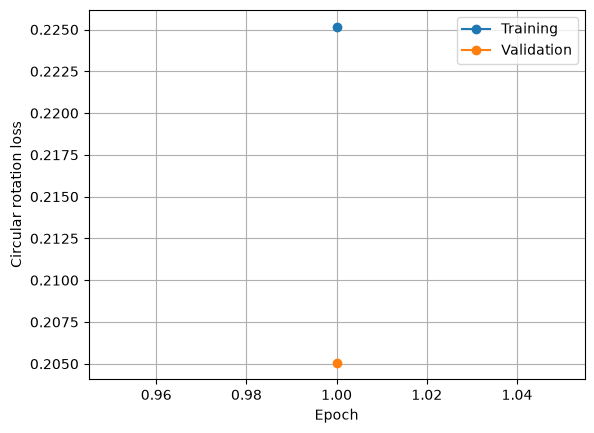

In [10]:
history_df = pd.DataFrame(history)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training",
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Circular rotation loss")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# Store results
run_dir = PROJECT_ROOT / "training_runs" / config["run_name"]
run_dir.mkdir(parents=True, exist_ok=True)

# Save trained model and everything needed to resume
torch.save(
    {
        "epoch": config["epochs"],
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "config": config,
        "history": history,
    },
    run_dir / "checkpoint.pt",
)

# Save losses separately for easy inspection
history_df = pd.DataFrame(history)
history_df.to_csv(run_dir / "history.csv", index=False)

print("Saved to:", run_dir)

Saved to: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/training_runs/cpu_20min_test_boats
